In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
flower = pd.read_csv('02_01_sakura_flowering_1953_2025.csv')
full_bloom = pd.read_csv('02_02_sakura_full_bloom_1953_2025.csv')

In [3]:
full_bloom.head(1)

,station_id,year,full_bloom_date
0,401,1953,30/5/1953


### check for null 

In [4]:
full_bloom.isnull().sum()

station_id            0
year                  0
full_bloom_date    1287
dtype: int64

### transform the date to day of year

In [5]:



full_bloom["full_bloom_date"] = pd.to_datetime(
    full_bloom["full_bloom_date"],
    dayfirst=True
)


full_bloom["full_bloom_doy"] = full_bloom["full_bloom_date"].dt.dayofyear


full_bloom[["station_id", "year", "full_bloom_date", "full_bloom_doy"]].head()

,station_id,year,full_bloom_date,full_bloom_doy
0,401,1953,1953-05-30,150.0
1,401,1954,1954-05-27,147.0
2,401,1955,1955-05-23,143.0
3,401,1956,1956-05-14,135.0
4,401,1957,1957-05-22,142.0


## simple visualization(before dealing with null values )

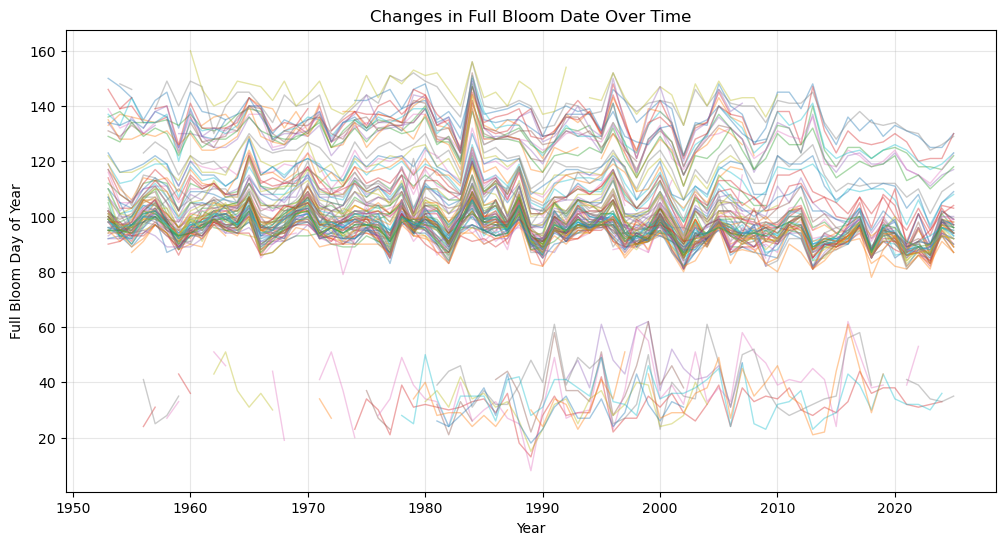

In [6]:
plt.figure(figsize=(12, 6))

for station_id, group in full_bloom.groupby("station_id"):
    group = group.sort_values("year")
    
    plt.plot(
        group["year"],
        group["full_bloom_doy"],
        alpha=0.4,
        linewidth=1
    )

plt.xlabel("Year")
plt.ylabel("Full Bloom Day of Year")
plt.title("Changes in Full Bloom Date Over Time")

plt.grid(alpha=0.3)
plt.show()

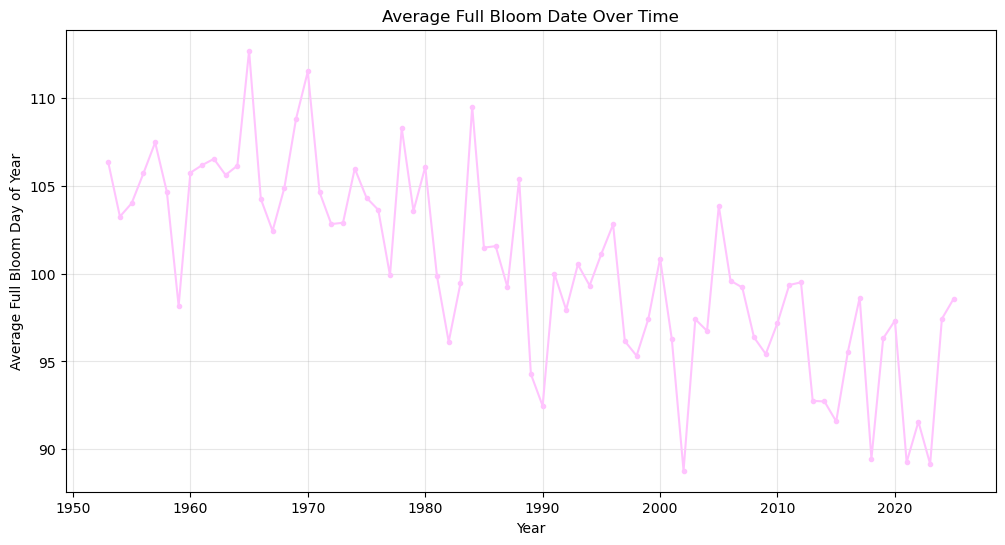

In [7]:
yearly_avg = (
    full_bloom
    .groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_avg["year"],
    yearly_avg["full_bloom_doy"],
    marker="o",
    markersize=3,
    color ="#FFC4FE"
)

plt.xlabel("Year")
plt.ylabel("Average Full Bloom Day of Year")
plt.title("Average Full Bloom Date Over Time")

plt.grid(alpha=0.3)
plt.show()

The average full bloom date shows a clear downward trend over time, suggesting that cherry blossoms are generally reaching full bloom earlier in recent decades. Despite substantial variation across stations and years, this overall shift is visible across the dataset.

### drop null

In [8]:
full_bloom = full_bloom.dropna(subset=["full_bloom_doy"])

### Visualization after dropping null

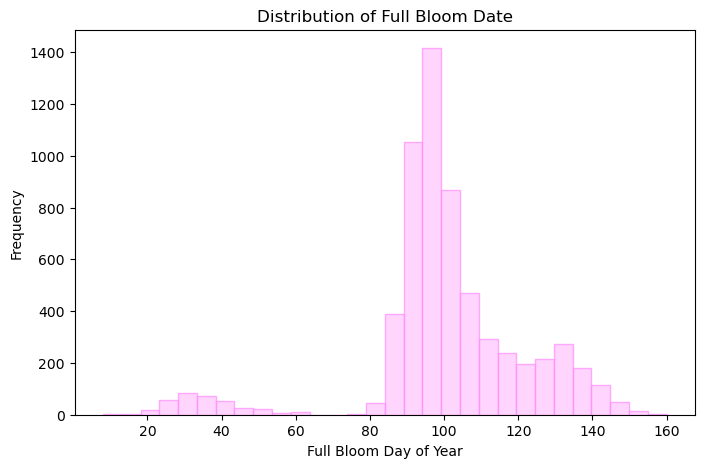

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(full_bloom["full_bloom_doy"], bins=30, edgecolor="#FF89FD",fill=True, alpha=0.7, color="#FFC4FE")

plt.xlabel("Full Bloom Day of Year")
plt.ylabel("Frequency")
plt.title("Distribution of Full Bloom Date")

plt.show()

Full bloom dates are mainly concentrated around days 90–110, while smaller groups bloom much earlier or later, indicating substantial variation across stations.

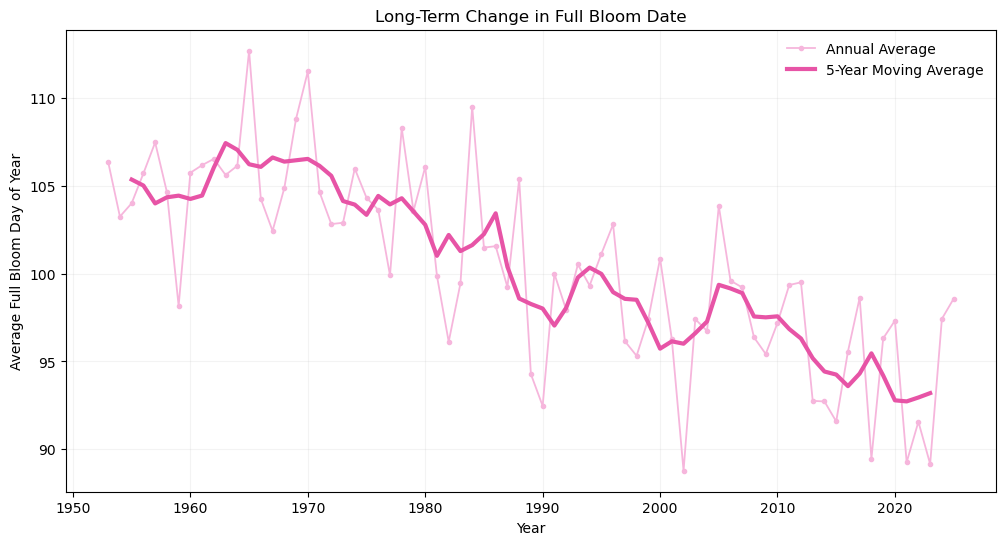

In [10]:
yearly = (
    full_bloom.groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

yearly["rolling_5yr"] = (
    yearly["full_bloom_doy"]
    .rolling(5, center=True)
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly["year"],
    yearly["full_bloom_doy"],
    color="#f6b6dc",
    marker="o",
    markersize=3,
    linewidth=1.3,
    label="Annual Average"
)

plt.plot(
    yearly["year"],
    yearly["rolling_5yr"],
    color="#e754a6",
    linewidth=3,
    label="5-Year Moving Average"
)

plt.xlabel("Year")
plt.ylabel("Average Full Bloom Day of Year")
plt.title("Long-Term Change in Full Bloom Date")
plt.legend(frameon=False)
plt.grid(alpha=0.15)
plt.show()

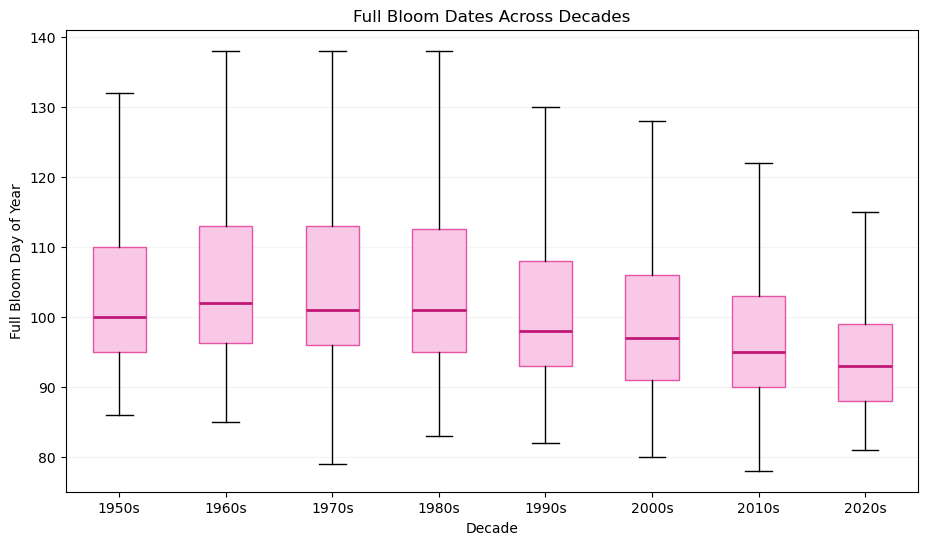

In [11]:
full_bloom["decade"] = (full_bloom["year"] // 10) * 10

decades = sorted(full_bloom["decade"].unique())

data = [
    full_bloom.loc[
        full_bloom["decade"] == decade,
        "full_bloom_doy"
    ]
    for decade in decades
]

plt.figure(figsize=(11, 6))

bp = plt.boxplot(
    data,
    tick_labels=[f"{d}s" for d in decades],
    patch_artist=True,
    showfliers=False
)

for box in bp["boxes"]:
    box.set_facecolor("#f8c8e6")
    box.set_edgecolor("#e754a6")

for median in bp["medians"]:
    median.set_color("#c21875")
    median.set_linewidth(2)

plt.xlabel("Decade")
plt.ylabel("Full Bloom Day of Year")
plt.title("Full Bloom Dates Across Decades")

plt.grid(axis="y", alpha=0.15)
plt.show()

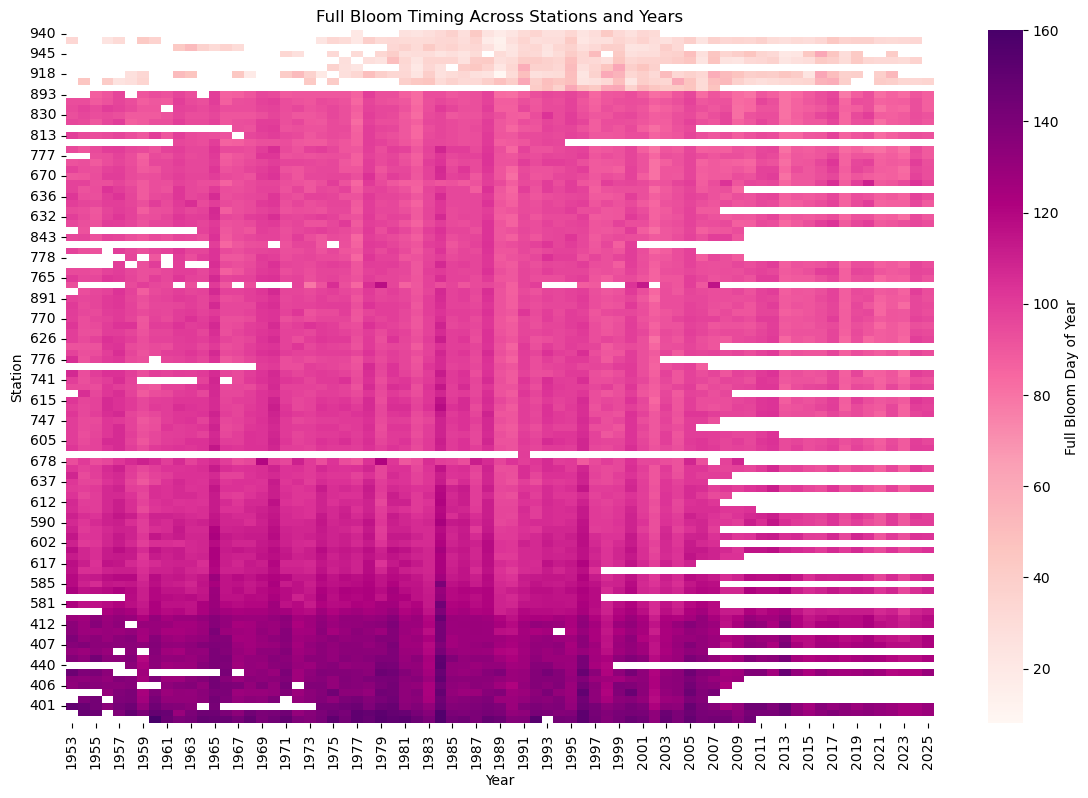

In [14]:
heatmap_data = full_bloom.pivot_table(
    index="station_id",
    columns="year",
    values="full_bloom_doy"
)


order = heatmap_data.mean(axis=1).sort_values().index
heatmap_data = heatmap_data.loc[order]

plt.figure(figsize=(14, 9))

sns.heatmap(
    heatmap_data,
    cmap="RdPu",
    cbar_kws={"label": "Full Bloom Day of Year"}
)

plt.xlabel("Year")
plt.ylabel("Station")
plt.title("Full Bloom Timing Across Stations and Years")

plt.show()

Full bloom timing varies substantially across stations, reflecting strong regional differences in flowering patterns. Despite these differences, many stations show a gradual shift toward earlier full bloom dates over time.

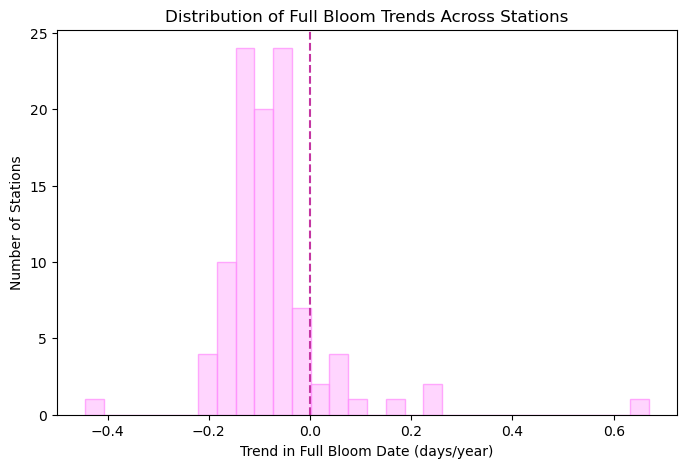

In [12]:
station_trends = []

for station_id, group in full_bloom.groupby("station_id"):
    
    if len(group) >= 10:
        slope = np.polyfit(
            group["year"],
            group["full_bloom_doy"],
            1
        )[0]
        
        station_trends.append(slope)

plt.figure(figsize=(8, 5))

plt.hist(station_trends, bins=30, edgecolor="#FF89FD", alpha=0.7, color="#FFC4FE")

plt.axvline(0, linestyle="--", color="#C436A2", label="No Trend")

plt.xlabel("Trend in Full Bloom Date (days/year)")
plt.ylabel("Number of Stations")
plt.title("Distribution of Full Bloom Trends Across Stations")

plt.show()

Most stations show negative trends, suggesting that full bloom dates have generally become earlier over time, although a few stations show later blooming trends.

In [18]:
# save cleaned dataset as csv
full_bloom[['station_id','year','full_bloom_date','full_bloom_doy']].to_csv('cleaned_full_bloom_data.csv', index=False)